In [ ]:
# ============================================================
# CELL 1: Mount Drive & Install
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

!pip install transformers torch librosa soundfile \
             scikit-learn matplotlib seaborn \
             imbalanced-learn scipy -q

print("✅ All packages installed!")

Mounted at /content/drive
✅ All packages installed!


In [ ]:
# ============================================================
# CELL 2: Imports & Config
# ============================================================
import os, re, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from tqdm import tqdm
warnings.filterwarnings('ignore')

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from transformers import (
    AutoTokenizer, AutoModel,
    Wav2Vec2Processor, Wav2Vec2Model,
    get_linear_schedule_with_warmup
)
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, auc
)
from sklearn.utils.class_weight import compute_class_weight

# ── Paths ──
DRIVE_BASE   = '/content/drive/MyDrive'
IEMOCAP_PATH = '/content/drive/MyDrive/IEMOCAP dataset/IEMOCAP_full_release_withoutVideos-001/IEMOCAP_full_release'
OUTPUT_DIR   = f'{DRIVE_BASE}/Mini Project/emotion_project/multimodal/outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Config ──
SEED        = 42
BATCH_SIZE  = 16
EPOCHS      = 10
MAX_LEN     = 128
MAX_AUDIO   = 16000 * 4   # 4 seconds
NUM_CLASSES = 4
EMOTIONS    = ['ang', 'hap', 'neu', 'sad']
EMOTION_NAMES = ['Anger', 'Happiness', 'Neutral', 'Sadness']

torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Device     : {device}")
print(f"✅ Output dir : {OUTPUT_DIR}")

✅ Device     : cuda
✅ Output dir : /content/drive/MyDrive/Mini Project/emotion_project/multimodal/outputs


**Multomodal - MLP( Audio features - Wav2Vec2 , Text features - ROBERTA + CNN , Cross Modal Attention)**

In [ ]:
# ============================================================
# CELL 3: Load IEMOCAP — audio paths, transcripts, labels
# ============================================================
# Parses all 5 sessions, extracts wav paths + transcripts
# Maps exc → hap, keeps only 4 emotions

valid_emotions = ['ang', 'hap', 'sad', 'neu', 'exc']
wav_paths, transcripts, labels, utterance_ids = [], [], [], []

for session in range(1, 6):
    session_path = os.path.join(IEMOCAP_PATH, f'Session{session}')
    wav_files    = glob.glob(
        os.path.join(session_path, 'sentences', 'wav', '**/*.wav'),
        recursive=True)

    for wav_file in wav_files:
        file_id = os.path.basename(wav_file).replace('.wav', '')
        parts   = file_id.split('_')

        ann_name = ('_'.join(parts[:2]) + '.txt'
                    if 'impro' in file_id
                    else '_'.join(parts[:3]) + '.txt')

        ann_path   = os.path.join(
            session_path, 'dialog', 'EmoEvaluation', ann_name)
        trans_path = os.path.join(
            session_path, 'dialog', 'transcriptions', ann_name)

        if not os.path.exists(ann_path) or \
           not os.path.exists(trans_path):
            continue

        # ── Get emotion ──
        emotion = None
        with open(ann_path) as f:
            for line in f:
                if file_id in line:
                    emotion = line.strip().split()[4]
                    break

        if emotion not in valid_emotions:
            continue
        if emotion == 'exc':
            emotion = 'hap'

        # ── Get transcript ──
        text = ''
        with open(trans_path) as f:
            for line in f:
                if file_id in line:
                    text = ' '.join(line.strip().split()[2:])
                    break

        if text == '':
            continue

        wav_paths.append(wav_file)
        transcripts.append(text)
        labels.append(emotion)
        utterance_ids.append(file_id)

print(f"✅ Total samples : {len(wav_paths)}")
from collections import Counter
print(f"Distribution   : {Counter(labels)}")

✅ Total samples : 5530
Distribution   : Counter({'neu': 1708, 'hap': 1635, 'ang': 1103, 'sad': 1084})


In [ ]:
# ============================================================
# CELL 4: Encode labels, stratified split, class weights
# ============================================================
from collections import Counter

le = LabelEncoder()
y  = le.fit_transform(labels)

print(f"Classes: {list(le.classes_)} → {EMOTION_NAMES}")
print(f"Distribution: {Counter(y)}")

# ── Stratified 80/10/10 split ──
(X_tr_wav, X_tmp_wav,
 X_tr_txt, X_tmp_txt,
 X_tr_id,  X_tmp_id,
 y_tr,     y_tmp) = train_test_split(
    wav_paths, transcripts, utterance_ids, y,
    test_size=0.2, stratify=y, random_state=SEED)

(X_vl_wav, X_te_wav,
 X_vl_txt, X_te_txt,
 X_vl_id,  X_te_id,
 y_vl,     y_te) = train_test_split(
    X_tmp_wav, X_tmp_txt, X_tmp_id, y_tmp,
    test_size=0.5, stratify=y_tmp, random_state=SEED)

print(f"\nTrain: {len(X_tr_wav)} | Val: {len(X_vl_wav)} | Test: {len(X_te_wav)}")

# ── Class weights for Focal Loss ──
cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_tr), y=y_tr)
class_weights = torch.tensor(cw, dtype=torch.float).to(device)
print(f"\nClass weights: {dict(zip(EMOTION_NAMES, cw.round(3)))}")

# ── Weighted sampler for balanced batches ──
sample_weights = torch.tensor([cw[y] for y in y_tr], dtype=torch.float)
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True)

Classes: [np.str_('ang'), np.str_('hap'), np.str_('neu'), np.str_('sad')] → ['Anger', 'Happiness', 'Neutral', 'Sadness']
Distribution: Counter({np.int64(2): 1708, np.int64(1): 1635, np.int64(0): 1103, np.int64(3): 1084})

Train: 4424 | Val: 553 | Test: 553

Class weights: {'Anger': np.float64(1.253), 'Happiness': np.float64(0.846), 'Neutral': np.float64(0.81), 'Sadness': np.float64(1.276)}


In [ ]:
# ============================================================
# CELL 5: Focal Loss + Multimodal Dataset class
# ============================================================

class FocalLoss(nn.Module):
    def __init__(self, alpha, gamma=2.0):
        super().__init__()
        self.alpha = alpha.to(device)
        self.gamma = gamma

    def forward(self, logits, targets):
        ce    = nn.functional.cross_entropy(
            logits, targets, weight=self.alpha, reduction='none')
        pt    = torch.exp(-ce)
        focal = ((1 - pt) ** self.gamma) * ce
        return focal.mean()

focal_loss = FocalLoss(alpha=class_weights)
print("✅ Focal Loss ready!")


class MultimodalDataset(Dataset):
    """
    Loads audio waveform + tokenized text for each utterance.
    Audio: raw waveform padded/truncated to 4 seconds
    Text : RoBERTa tokenized
    """
    def __init__(self, wav_paths, texts, labels,
                 tokenizer, max_len=MAX_LEN, max_audio=MAX_AUDIO):
        self.wav_paths = list(wav_paths)
        self.texts     = list(texts)
        self.labels    = list(labels)
        self.tokenizer = tokenizer
        self.max_len   = max_len
        self.max_audio = max_audio

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        import librosa

        # ── Audio ──
        signal, sr = librosa.load(self.wav_paths[idx], sr=16000)
        if len(signal) > self.max_audio:
            signal = signal[:self.max_audio]
        else:
            signal = np.pad(signal, (0, self.max_audio - len(signal)))
        audio = torch.tensor(signal, dtype=torch.float32)

        # ── Text ──
        enc = self.tokenizer(
            str(self.texts[idx]),
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        return {
            'audio'         : audio,
            'input_ids'     : enc['input_ids'].squeeze(),
            'attention_mask': enc['attention_mask'].squeeze(),
            'label'         : torch.tensor(self.labels[idx],
                                           dtype=torch.long)
        }

print("✅ Dataset class ready!")

✅ Focal Loss ready!
✅ Dataset class ready!


In [ ]:
# ============================================================
# CELL 6: Cross-Modal Attention Fusion Model
# ============================================================
# Architecture:
#   Audio branch  : Wav2Vec2-base → mean pool → projection
#   Text branch   : RoBERTa-base → CNN → projection
#   Fusion        : Cross-modal attention + concatenation
#   Classifier    : MLP with dropout → 4 classes
#
# This is significantly stronger than simple concatenation
# used in the teammate's notebook

class CrossModalAttention(nn.Module):
    """
    Lets audio features attend to text features and vice versa.
    This is the key innovation over simple feature concatenation.
    """
    def __init__(self, dim=256):
        super().__init__()
        self.attn_audio_to_text = nn.MultiheadAttention(
            embed_dim=dim, num_heads=4, batch_first=True)
        self.attn_text_to_audio = nn.MultiheadAttention(
            embed_dim=dim, num_heads=4, batch_first=True)
        self.norm1 = nn.LayerNorm(dim)
        self.norm2 = nn.LayerNorm(dim)

    def forward(self, audio_feat, text_feat):
        # audio attends to text
        a2t, _ = self.attn_audio_to_text(
            audio_feat.unsqueeze(1),
            text_feat.unsqueeze(1),
            text_feat.unsqueeze(1))
        # text attends to audio
        t2a, _ = self.attn_text_to_audio(
            text_feat.unsqueeze(1),
            audio_feat.unsqueeze(1),
            audio_feat.unsqueeze(1))
        audio_out = self.norm1(audio_feat + a2t.squeeze(1))
        text_out  = self.norm2(text_feat  + t2a.squeeze(1))
        return audio_out, text_out


class MultimodalFusionModel(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()

        # ── Audio encoder: Wav2Vec2-base ──
        self.audio_encoder = Wav2Vec2Model.from_pretrained(
            'facebook/wav2vec2-base')
        audio_hidden = 768

        # ── Text encoder: RoBERTa-base + CNN ──
        self.text_encoder = AutoModel.from_pretrained('roberta-base')
        text_hidden = 768
        self.text_convs = nn.ModuleList([
            nn.Conv1d(text_hidden, 128, kernel_size=k, padding=k//2)
            for k in [2, 3, 4]])
        self.text_proj = nn.Linear(128 * 3, 256)

        # ── Audio projection ──
        self.audio_proj = nn.Linear(audio_hidden, 256)

        # ── Cross-modal attention fusion ──
        self.cross_attn = CrossModalAttention(dim=256)

        # ── Classifier ──
        self.drop = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(256 * 2, 256),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, audio, input_ids, attention_mask):
        # ── Audio features ──
        audio_out  = self.audio_encoder(audio).last_hidden_state
        audio_feat = audio_out.mean(dim=1)          # mean pool
        audio_feat = self.audio_proj(audio_feat)    # → 256

        # ── Text features ──
        text_out  = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask).last_hidden_state
        x = text_out.permute(0, 2, 1)              # CNN expects (B, C, L)
        pooled = [torch.relu(conv(x)).max(dim=2)[0]
                  for conv in self.text_convs]
        text_feat = self.text_proj(
            torch.cat(pooled, dim=1))               # → 256

        # ── Cross-modal attention fusion ──
        audio_fused, text_fused = self.cross_attn(audio_feat, text_feat)

        # ── Concatenate + classify ──
        fused = torch.cat([audio_fused, text_fused], dim=1)  # → 512
        return self.classifier(self.drop(fused))

print("✅ Multimodal Fusion Model defined!")
print("   Audio  : Wav2Vec2-base → mean pool → Linear(768→256)")
print("   Text   : RoBERTa-base → CNN → Linear(384→256)")
print("   Fusion : Cross-modal attention → MLP → 4 classes")

✅ Multimodal Fusion Model defined!
   Audio  : Wav2Vec2-base → mean pool → Linear(768→256)
   Text   : RoBERTa-base → CNN → Linear(384→256)
   Fusion : Cross-modal attention → MLP → 4 classes


In [ ]:
# ============================================================
# CELL 7: Training and evaluation functions
# ============================================================

def train_epoch(model, loader, optimizer, scheduler):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for batch in loader:
        audio = batch['audio'].to(device)
        ids   = batch['input_ids'].to(device)
        mask  = batch['attention_mask'].to(device)
        lbl   = batch['label'].to(device)

        optimizer.zero_grad()
        logits = model(audio, ids, mask)
        loss   = focal_loss(logits, lbl)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        correct    += (logits.argmax(1) == lbl).sum().item()
        total      += lbl.size(0)
    return total_loss / len(loader), correct / total


@torch.no_grad()
def eval_model(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    total_loss = 0
    for batch in loader:
        audio = batch['audio'].to(device)
        ids   = batch['input_ids'].to(device)
        mask  = batch['attention_mask'].to(device)
        lbl   = batch['label'].to(device)

        logits = model(audio, ids, mask)
        loss   = focal_loss(logits, lbl)
        total_loss += loss.item()

        probs = torch.softmax(logits, dim=1)
        all_preds.extend(logits.argmax(1).cpu().numpy())
        all_labels.extend(lbl.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='weighted')
    return (total_loss / len(loader), acc, f1,
            all_preds, all_labels, np.array(all_probs))

print("✅ Train/eval functions ready!")

✅ Train/eval functions ready!


In [ ]:
# ============================================================
# CELL 8: Build dataloaders and run training
# ============================================================

# ── Load tokenizer ──
tokenizer = AutoTokenizer.from_pretrained('roberta-base')

train_ds = MultimodalDataset(X_tr_wav, X_tr_txt, y_tr, tokenizer)
val_ds   = MultimodalDataset(X_vl_wav, X_vl_txt, y_vl, tokenizer)
test_ds  = MultimodalDataset(X_te_wav, X_te_txt, y_te, tokenizer)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE,
                          sampler=sampler, num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=2)

# ── Init model ──
model     = MultimodalFusionModel().to(device)
optimizer = AdamW(model.parameters(), lr=1e-5, weight_decay=0.01)
total_steps  = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * 0.1)
scheduler = get_linear_schedule_with_warmup(
    optimizer, warmup_steps, total_steps)

# ── Training loop ──
best_f1, patience_ctr = 0, 0
history = {'train_loss':[], 'val_loss':[],
           'val_acc':[], 'val_f1':[]}

print(f"{'Epoch':>6} {'Train Loss':>11} {'Val Loss':>9} "
      f"{'Val Acc':>8} {'Val F1':>7} {'Status':>12}")
print("─" * 62)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc              = train_epoch(
        model, train_loader, optimizer, scheduler)
    vl_loss, vl_acc, vl_f1,_,_,_ = eval_model(model, val_loader)

    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)
    history['val_acc'].append(vl_acc)
    history['val_f1'].append(vl_f1)

    if vl_f1 > best_f1:
        best_f1 = vl_f1
        torch.save(model.state_dict(),
                   f'{OUTPUT_DIR}/multimodal_best.pt')
        patience_ctr = 0
        status = '✅ saved'
    else:
        patience_ctr += 1
        status = f'patience {patience_ctr}/3'

    print(f"{epoch:>6}  {tr_loss:>10.4f}  {vl_loss:>8.4f}  "
          f"{vl_acc:>7.4f}  {vl_f1:>6.4f}  {status}")

    if patience_ctr >= 3:
        print(f"\n⏹ Early stopping at epoch {epoch}")
        break

print(f"\n✅ Training complete! Best Val F1: {best_f1:.4f}")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

... (4 outputs left out)

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


 Epoch  Train Loss  Val Loss  Val Acc  Val F1       Status
──────────────────────────────────────────────────────────────
     1      0.6904    0.4441   0.5027  0.4595  ✅ saved
     2      0.3306    0.2896   0.6817  0.6637  ✅ saved
     3      0.2006    0.2677   0.7360  0.7241  ✅ saved
     4      0.1425    0.2183   0.7685  0.7656  ✅ saved
     5      0.1015    0.2395   0.7649  0.7609  patience 1/3
     6      0.0786    0.2453   0.7776  0.7756  ✅ saved
     7      0.0654    0.2393   0.8011  0.7993  ✅ saved
     8      0.0455    0.2338   0.8047  0.8018  ✅ saved
     9      0.0383    0.2315   0.8083  0.8077  ✅ saved
    10      0.0335    0.2282   0.8119  0.8104  ✅ saved

✅ Training complete! Best Val F1: 0.8104


In [ ]:
# ── Initialize model (skip training, load from saved weights) ──
model = MultimodalFusionModel().to(device)
print("✅ Model initialized, ready to load weights!")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/380M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/380M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


✅ Model initialized, ready to load weights!


In [ ]:
# ── Build dataloaders (skip training, just need test_loader) ──
tokenizer = AutoTokenizer.from_pretrained('roberta-base')

test_ds     = MultimodalDataset(X_te_wav, X_te_txt, y_te, tokenizer)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2)
print("✅ test_loader ready!")

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

✅ test_loader ready!


In [ ]:
# ============================================================
# CELL 9: Load best model and evaluate on test set
# ============================================================

model.load_state_dict(
    torch.load(f'{OUTPUT_DIR}/multimodal_best.pt'))

_, test_acc, test_f1, test_preds, test_labels, test_probs = \
    eval_model(model, test_loader)

print("=" * 55)
print("  FINAL TEST RESULTS — MULTIMODAL FUSION")
print("=" * 55)
print(f"  Accuracy  : {test_acc*100:.2f}%")
print(f"  F1 Score  : {test_f1:.4f}")
print("=" * 55)
print("\nClassification Report:")
print(classification_report(
    test_labels, test_preds,
    target_names=EMOTION_NAMES, digits=4))

# ── Save metrics ──
metrics = {
    'test_accuracy'  : round(float(test_acc), 4),
    'test_f1'        : round(float(test_f1),  4),
    'model'          : 'Wav2Vec2 + RoBERTa-CNN + Cross-Attention',
    'num_classes'    : NUM_CLASSES,
    'classes'        : EMOTION_NAMES,
    'imbalance'      : 'Focal Loss + Weighted Sampler'
}
with open(f'{OUTPUT_DIR}/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)
print("✅ Metrics saved!")

  FINAL TEST RESULTS — MULTIMODAL FUSION
  Accuracy  : 76.31%
  F1 Score  : 0.7617

Classification Report:
              precision    recall  f1-score   support

       Anger     0.8018    0.8091    0.8054       110
   Happiness     0.7875    0.7683    0.7778       164
     Neutral     0.7261    0.6667    0.6951       171
     Sadness     0.7440    0.8611    0.7983       108

    accuracy                         0.7631       553
   macro avg     0.7649    0.7763    0.7692       553
weighted avg     0.7629    0.7631    0.7617       553

✅ Metrics saved!


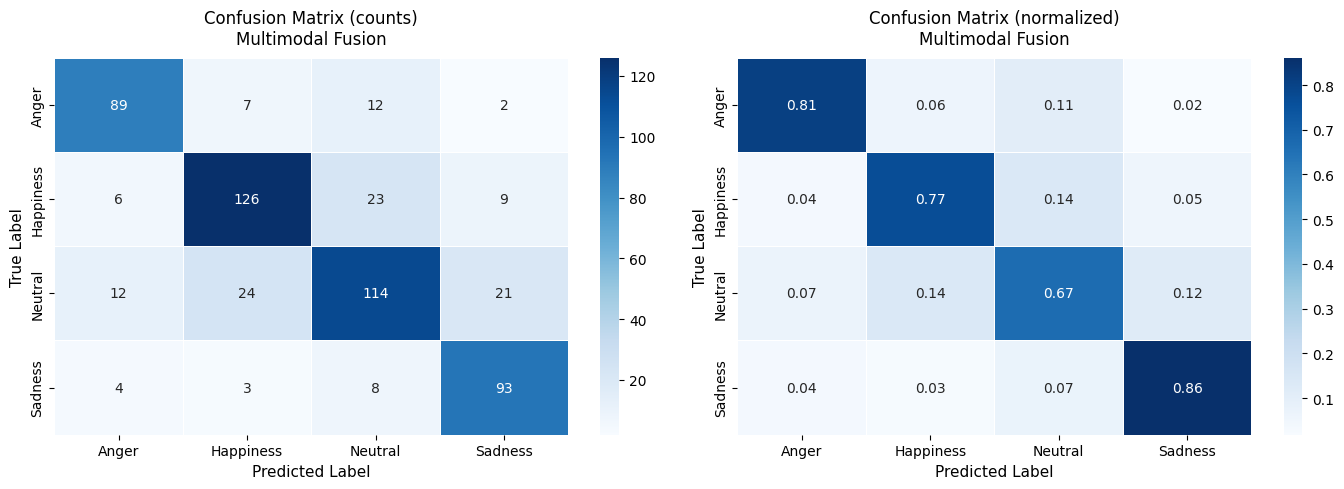

✅ Confusion matrix saved!


In [ ]:
 # ============================================================
# CELL 10: Confusion matrix (counts + normalized)
# ============================================================

cm      = confusion_matrix(test_labels, test_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=EMOTION_NAMES,
            yticklabels=EMOTION_NAMES,
            linewidths=0.5, linecolor='white', ax=axes[0])
axes[0].set_title('Confusion Matrix (counts)\nMultimodal Fusion',
                  fontsize=12, pad=10)
axes[0].set_ylabel('True Label', fontsize=11)
axes[0].set_xlabel('Predicted Label', fontsize=11)

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=EMOTION_NAMES,
            yticklabels=EMOTION_NAMES,
            linewidths=0.5, linecolor='white', ax=axes[1])
axes[1].set_title('Confusion Matrix (normalized)\nMultimodal Fusion',
                  fontsize=12, pad=10)
axes[1].set_ylabel('True Label', fontsize=11)
axes[1].set_xlabel('Predicted Label', fontsize=11)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/confusion_matrix.png', dpi=150)
plt.show()
print("✅ Confusion matrix saved!")

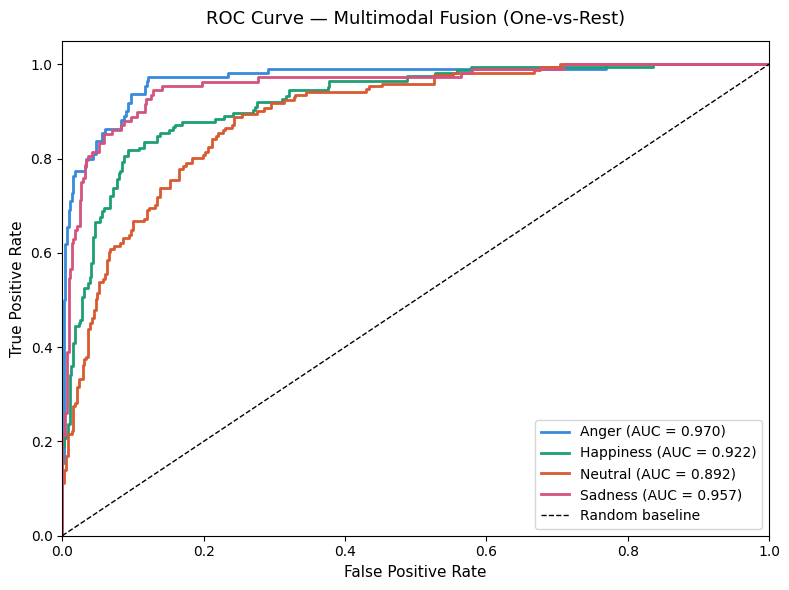

✅ ROC curve saved!


In [ ]:
# ============================================================
# CELL 11: ROC curve — One vs Rest for all 4 emotions
# ============================================================

y_test_bin = label_binarize(
    test_labels, classes=list(range(NUM_CLASSES)))
colors = ['#378ADD', '#1D9E75', '#D85A30', '#D4537E']

fpr, tpr, roc_auc = {}, {}, {}
plt.figure(figsize=(8, 6))

for i, (color, label) in enumerate(zip(colors, EMOTION_NAMES)):
    fpr[i], tpr[i], _ = roc_curve(
        y_test_bin[:, i], test_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'{label} (AUC = {roc_auc[i]:.3f})')

plt.plot([0,1],[0,1],'k--',lw=1, label='Random baseline')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC Curve — Multimodal Fusion (One-vs-Rest)',
          fontsize=13, pad=12)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/roc_curve.png', dpi=150)
plt.show()
print("✅ ROC curve saved!")

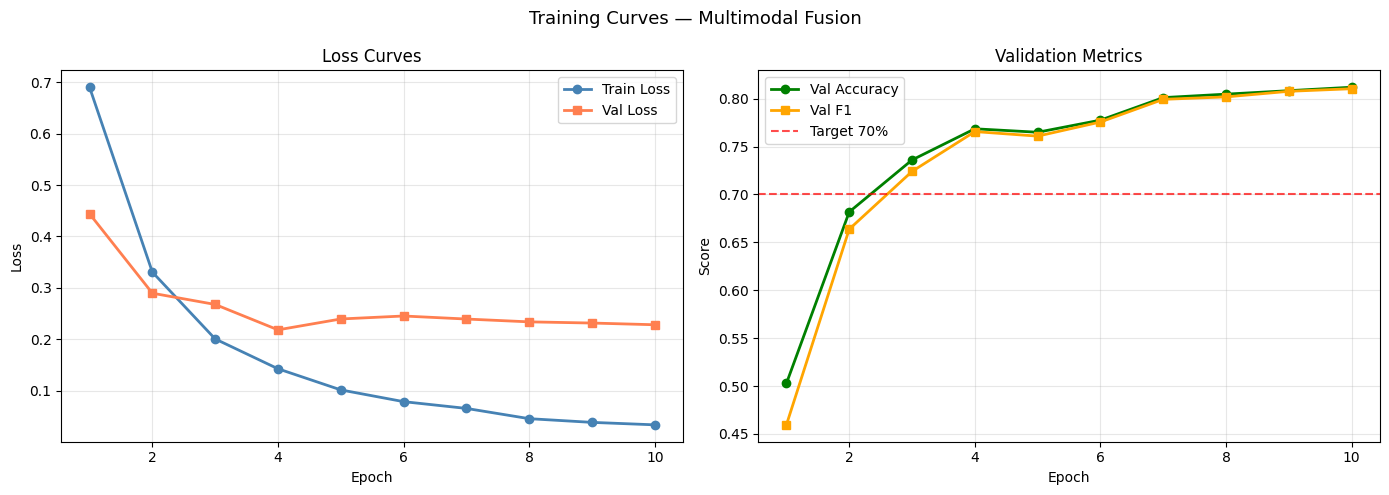

✅ Training curves saved!


In [ ]:
# ============================================================
# CELL 12: Training curves
# ============================================================

epochs_ran = range(1, len(history['train_loss']) + 1)
fig, axes  = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_ran, history['train_loss'],
             label='Train Loss', color='steelblue',
             marker='o', lw=2)
axes[0].plot(epochs_ran, history['val_loss'],
             label='Val Loss', color='coral',
             marker='s', lw=2)
axes[0].set_title('Loss Curves', fontsize=12)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_ran, history['val_acc'],
             label='Val Accuracy', color='green',
             marker='o', lw=2)
axes[1].plot(epochs_ran, history['val_f1'],
             label='Val F1', color='orange',
             marker='s', lw=2)
axes[1].axhline(0.70, color='red', linestyle='--',
                alpha=0.7, label='Target 70%')
axes[1].set_title('Validation Metrics', fontsize=12)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Score')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle('Training Curves — Multimodal Fusion', fontsize=13)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/training_curves.png', dpi=150)
plt.show()
print("✅ Training curves saved!")

In [ ]:
# ============================================================
# CELL 13: Emotion trend analysis on test conversations
# ============================================================

VAD_MAP = {
    'ang': {'valence': -0.60, 'arousal': 0.80,
            'dominance': 0.70, 'name': 'Anger'    },
    'hap': {'valence':  0.80, 'arousal': 0.70,
            'dominance': 0.60, 'name': 'Happiness'},
    'neu': {'valence':  0.00, 'arousal': 0.50,
            'dominance': 0.50, 'name': 'Neutral'  },
    'sad': {'valence': -0.70, 'arousal': 0.30,
            'dominance': 0.40, 'name': 'Sadness'  },
}
EMOTION_COLORS = {
    'ang': '#D85A30', 'hap': '#378ADD',
    'neu': '#888780', 'sad': '#1D9E75'
}

# ── Build conversation dataframe from test predictions ──
pred_emotions = le.inverse_transform(test_preds)
records = []
for idx, (file_id, pred) in enumerate(
        zip(X_te_id, pred_emotions)):
    parts   = file_id.split('_')
    conv_id = '_'.join(parts[:2])
    match   = re.search(r'[MF](\d+)', file_id)
    utt_id  = int(match.group(1)) if match else idx
    records.append({
        'conversation_id' : conv_id,
        'utterance_id'    : utt_id,
        'predicted_emotion': pred
    })

df_trend = pd.DataFrame(records).sort_values(
    ['conversation_id', 'utterance_id'])

TREND_DIR = f'{OUTPUT_DIR}/conversation_plots'
os.makedirs(TREND_DIR, exist_ok=True)

all_stats = []
conversations = df_trend['conversation_id'].unique()

print(f"Processing {len(conversations)} conversations...\n")

for i, conv_id in enumerate(conversations):
    conv = df_trend[df_trend['conversation_id'] == conv_id]
    emo_list = conv['predicted_emotion'].tolist()
    if len(emo_list) < 2:
        continue

    val = np.array([VAD_MAP[e]['valence']   for e in emo_list])
    aro = np.array([VAD_MAP[e]['arousal']   for e in emo_list])
    dom = np.array([VAD_MAP[e]['dominance'] for e in emo_list])

    # ── Changed: sigma=1 (was 1.5) ──
    val_s = gaussian_filter1d(val.astype(float), sigma=1)
    aro_s = gaussian_filter1d(aro.astype(float), sigma=1)
    dom_s = gaussian_filter1d(dom.astype(float), sigma=1)

    trend    = float(val[-1]) - float(val[0])
    variance = float(np.var(val))
    transitions = sum(1 for j in range(1, len(emo_list))
                      if emo_list[j] != emo_list[j-1])
    dominant = max(set(emo_list), key=emo_list.count)

    direction = ("Overall Positive Shift" if trend > 0.15
                 else "Overall Negative Shift" if trend < -0.15
                 else "Emotionally Stable")
    stability = ("High fluctuations" if variance > 0.2
                 else "Moderate variations" if variance > 0.1
                 else "Stable mood")

    all_stats.append({
        'conversation_id' : conv_id,
        'num_utterances'  : len(emo_list),
        'mean_valence'    : round(float(np.mean(val)), 4),
        'max_valence'     : round(float(np.max(val)),  4),
        'min_valence'     : round(float(np.min(val)),  4),
        'valence_variance': round(variance, 4),
        'num_transitions' : transitions,
        'dominant_emotion': VAD_MAP[dominant]['name'],
        'trend_direction' : direction,
        'stability'       : stability,
    })

    # ── Added: conclusion prints with 📌 ──
    if i < 10:
        print(f"  📌 {direction}")
        print(f"  📌 {stability}")
        print(f"  📌 Dominant emotion: {VAD_MAP[dominant]['name']}")

    # ── Plot first 10 ──
    if i < 10:
        x = np.arange(len(emo_list))
        fig, axes = plt.subplots(
            1, 2, figsize=(13, 4),
            gridspec_kw={'width_ratios': [3, 1]})

        ax = axes[0]
        for j, emo in enumerate(emo_list):
            ax.axvspan(j-0.5, j+0.5, alpha=0.07,
                       color=EMOTION_COLORS.get(emo, '#888780'))
        ax.scatter(x, val, alpha=0.2, color='#378ADD', s=15)
        ax.scatter(x, aro, alpha=0.2, color='#D85A30', s=15)
        ax.plot(x, val_s, color='#378ADD', lw=2.5,
                label='Valence (pos/neg)')
        ax.plot(x, aro_s, color='#D85A30', lw=2.5,
                linestyle='--', label='Arousal (energy)')
        ax.plot(x, dom_s, color='#1D9E75', lw=2.5,
                linestyle=':', label='Dominance (control)')
        ax.axhline(y=0, color='#888780', linestyle=':',
                   lw=1, alpha=0.6)
        ax.set_xlim(-0.5, len(emo_list)-0.5)
        ax.set_ylim(-1.1, 1.1)
        ax.set_xlabel('Utterance Index', fontsize=10)
        ax.set_ylabel('Emotion Intensity', fontsize=10)
        ax.set_title(
            f'Multimodal Emotion Trend — {conv_id}',
            fontsize=11, pad=8)
        ax.legend(fontsize=8)
        ax.grid(axis='y', alpha=0.3)
        ax.text(0.01, 0.02,
                f"{direction}\n{stability}\nDominant: "
                f"{VAD_MAP[dominant]['name']}",
                transform=ax.transAxes, fontsize=7,
                verticalalignment='bottom',
                bbox=dict(boxstyle='round',
                          facecolor='#F1EFE8', alpha=0.8))

        ax2 = axes[1]
        emo_counts = {VAD_MAP[e]['name']: emo_list.count(e)
                      for e in ['ang','hap','neu','sad']
                      if e in emo_list}
        bars = ax2.barh(
            list(emo_counts.keys()),
            list(emo_counts.values()),
            color=[EMOTION_COLORS[e]
                   for e in ['ang','hap','neu','sad']
                   if e in emo_list],
            edgecolor='white', height=0.6)
        for bar, v in zip(bars, emo_counts.values()):
            ax2.text(bar.get_width()+0.2,
                     bar.get_y()+bar.get_height()/2,
                     str(v), va='center', fontsize=8)
        ax2.set_xlabel('Count', fontsize=9)
        ax2.set_title('Distribution', fontsize=10)

        plt.tight_layout()
        safe = conv_id.replace('/', '_').replace(' ', '_')
        plt.savefig(f'{TREND_DIR}/{safe}.png',
                    dpi=150, bbox_inches='tight')
        plt.close()
        print(f"  [{i+1:02d}] {conv_id:30s} | "
              f"utts: {len(emo_list):3d} | "
              f"transitions: {transitions:2d} | "
              f"dominant: {VAD_MAP[dominant]['name']}")

print(f"\n✅ Processed {len(all_stats)} conversations!")

Processing 103 conversations...

  📌 Overall Negative Shift
  📌 Stable mood
  📌 Dominant emotion: Anger
  [01] Ses01F_impro01                 | utts:   2 | transitions:  1 | dominant: Anger
  📌 Emotionally Stable
  📌 Stable mood
  📌 Dominant emotion: Sadness
  [02] Ses01F_impro02                 | utts:   2 | transitions:  0 | dominant: Sadness
  📌 Overall Negative Shift
  📌 Moderate variations
  📌 Dominant emotion: Happiness
  [03] Ses01F_impro03                 | utts:   3 | transitions:  1 | dominant: Happiness
  📌 Overall Negative Shift
  📌 Moderate variations
  📌 Dominant emotion: Neutral
  [04] Ses01F_impro04                 | utts:   7 | transitions:  2 | dominant: Neutral
  📌 Overall Positive Shift
  📌 High fluctuations
  📌 Dominant emotion: Anger
  [05] Ses01F_impro05                 | utts:   4 | transitions:  1 | dominant: Anger
  📌 Overall Positive Shift
  📌 Moderate variations
  📌 Dominant emotion: Sadness
  [06] Ses01F_impro06                 | utts:   3 | transitions:  1

Available conversation IDs (first 10):
  Ses01F_impro01
  Ses01F_impro02
  Ses01F_impro03
  Ses01F_impro04
  Ses01F_impro05
  Ses01F_impro06
  Ses01F_impro07
  Ses01F_script01
  Ses01F_script02
  Ses01F_script03

Enter conversation ID to analyze: Ses01F_impro07

  ANALYSIS: Ses01F_impro07
  Utterances   : 1
  Mean Valence : 0.0
  Max Valence  : 0.0
  Min Valence  : 0.0
  Variance     : 0.0
  Transitions  : 0
  Dominant     : Neutral

  📌 Emotionally Stable
  📌 Stable mood
  📌 Dominant emotion: Neutral



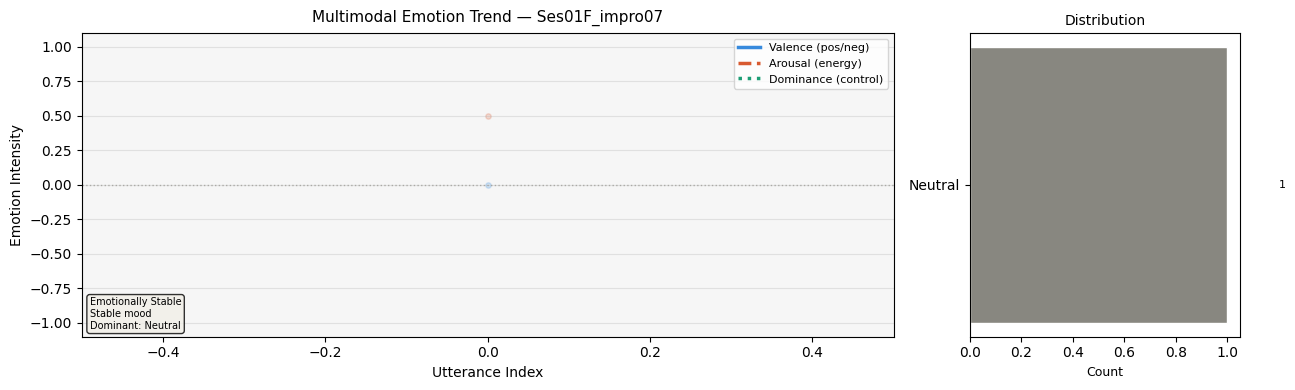

In [ ]:
# ============================================================
# CELL 13B: Interactive user query system
# ============================================================

def query_conversation(conv_id):
    subset = df_trend[df_trend['conversation_id'] == conv_id] \
             .sort_values('utterance_id')

    if len(subset) == 0:
        print(f"❌ Conversation '{conv_id}' not found!")
        print(f"\nAvailable IDs (sample):")
        for cid in df_trend['conversation_id'].unique()[:10]:
            print(f"  {cid}")
        return

    emo_list = subset['predicted_emotion'].tolist()
    val = np.array([VAD_MAP[e]['valence']   for e in emo_list])
    aro = np.array([VAD_MAP[e]['arousal']   for e in emo_list])
    dom = np.array([VAD_MAP[e]['dominance'] for e in emo_list])

    trend    = float(val[-1]) - float(val[0])
    variance = float(np.var(val))
    transitions = sum(1 for j in range(1, len(emo_list))
                      if emo_list[j] != emo_list[j-1])
    dominant = max(set(emo_list), key=emo_list.count)

    direction = ("Overall Positive Shift" if trend > 0.15
                 else "Overall Negative Shift" if trend < -0.15
                 else "Emotionally Stable")
    stability = ("High fluctuations" if variance > 0.2
                 else "Moderate variations" if variance > 0.1
                 else "Stable mood")

    print(f"\n{'='*55}")
    print(f"  ANALYSIS: {conv_id}")
    print(f"{'='*55}")
    print(f"  Utterances   : {len(emo_list)}")
    print(f"  Mean Valence : {round(float(np.mean(val)), 4)}")
    print(f"  Max Valence  : {round(float(np.max(val)), 4)}")
    print(f"  Min Valence  : {round(float(np.min(val)), 4)}")
    print(f"  Variance     : {round(variance, 4)}")
    print(f"  Transitions  : {transitions}")
    print(f"  Dominant     : {VAD_MAP[dominant]['name']}")
    print(f"\n  📌 {direction}")
    print(f"  📌 {stability}")
    print(f"  📌 Dominant emotion: {VAD_MAP[dominant]['name']}")
    print(f"{'='*55}\n")

    # ── Plot for queried conversation ──
    x     = np.arange(len(emo_list))
    val_s = gaussian_filter1d(val.astype(float), sigma=1)
    aro_s = gaussian_filter1d(aro.astype(float), sigma=1)
    dom_s = gaussian_filter1d(dom.astype(float), sigma=1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4),
                             gridspec_kw={'width_ratios': [3, 1]})
    ax = axes[0]
    for j, emo in enumerate(emo_list):
        ax.axvspan(j-0.5, j+0.5, alpha=0.07,
                   color=EMOTION_COLORS.get(emo, '#888780'))
    ax.scatter(x, val, alpha=0.2, color='#378ADD', s=15)
    ax.scatter(x, aro, alpha=0.2, color='#D85A30', s=15)
    ax.plot(x, val_s, color='#378ADD', lw=2.5, label='Valence (pos/neg)')
    ax.plot(x, aro_s, color='#D85A30', lw=2.5,
            linestyle='--', label='Arousal (energy)')
    ax.plot(x, dom_s, color='#1D9E75', lw=2.5,
            linestyle=':', label='Dominance (control)')
    ax.axhline(y=0, color='#888780', linestyle=':', lw=1, alpha=0.6)
    ax.set_xlim(-0.5, len(emo_list)-0.5)
    ax.set_ylim(-1.1, 1.1)
    ax.set_xlabel('Utterance Index', fontsize=10)
    ax.set_ylabel('Emotion Intensity', fontsize=10)
    ax.set_title(f'Multimodal Emotion Trend — {conv_id}',
                 fontsize=11, pad=8)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    ax.text(0.01, 0.02,
            f"{direction}\n{stability}\nDominant: {VAD_MAP[dominant]['name']}",
            transform=ax.transAxes, fontsize=7,
            verticalalignment='bottom',
            bbox=dict(boxstyle='round', facecolor='#F1EFE8', alpha=0.8))

    ax2 = axes[1]
    emo_counts = {VAD_MAP[e]['name']: emo_list.count(e)
                  for e in ['ang','hap','neu','sad'] if e in emo_list}
    bars = ax2.barh(list(emo_counts.keys()), list(emo_counts.values()),
                    color=[EMOTION_COLORS[e]
                           for e in ['ang','hap','neu','sad']
                           if e in emo_list],
                    edgecolor='white', height=0.6)
    for bar, v in zip(bars, emo_counts.values()):
        ax2.text(bar.get_width()+0.2,
                 bar.get_y()+bar.get_height()/2,
                 str(v), va='center', fontsize=8)
    ax2.set_xlabel('Count', fontsize=9)
    ax2.set_title('Distribution', fontsize=10)
    plt.tight_layout()
    plt.show()

print("Available conversation IDs (first 10):")
for cid in df_trend['conversation_id'].unique()[:10]:
    print(f"  {cid}")

print()
cid = input("Enter conversation ID to analyze: ")
query_conversation(cid.strip())

✅ Stats saved!


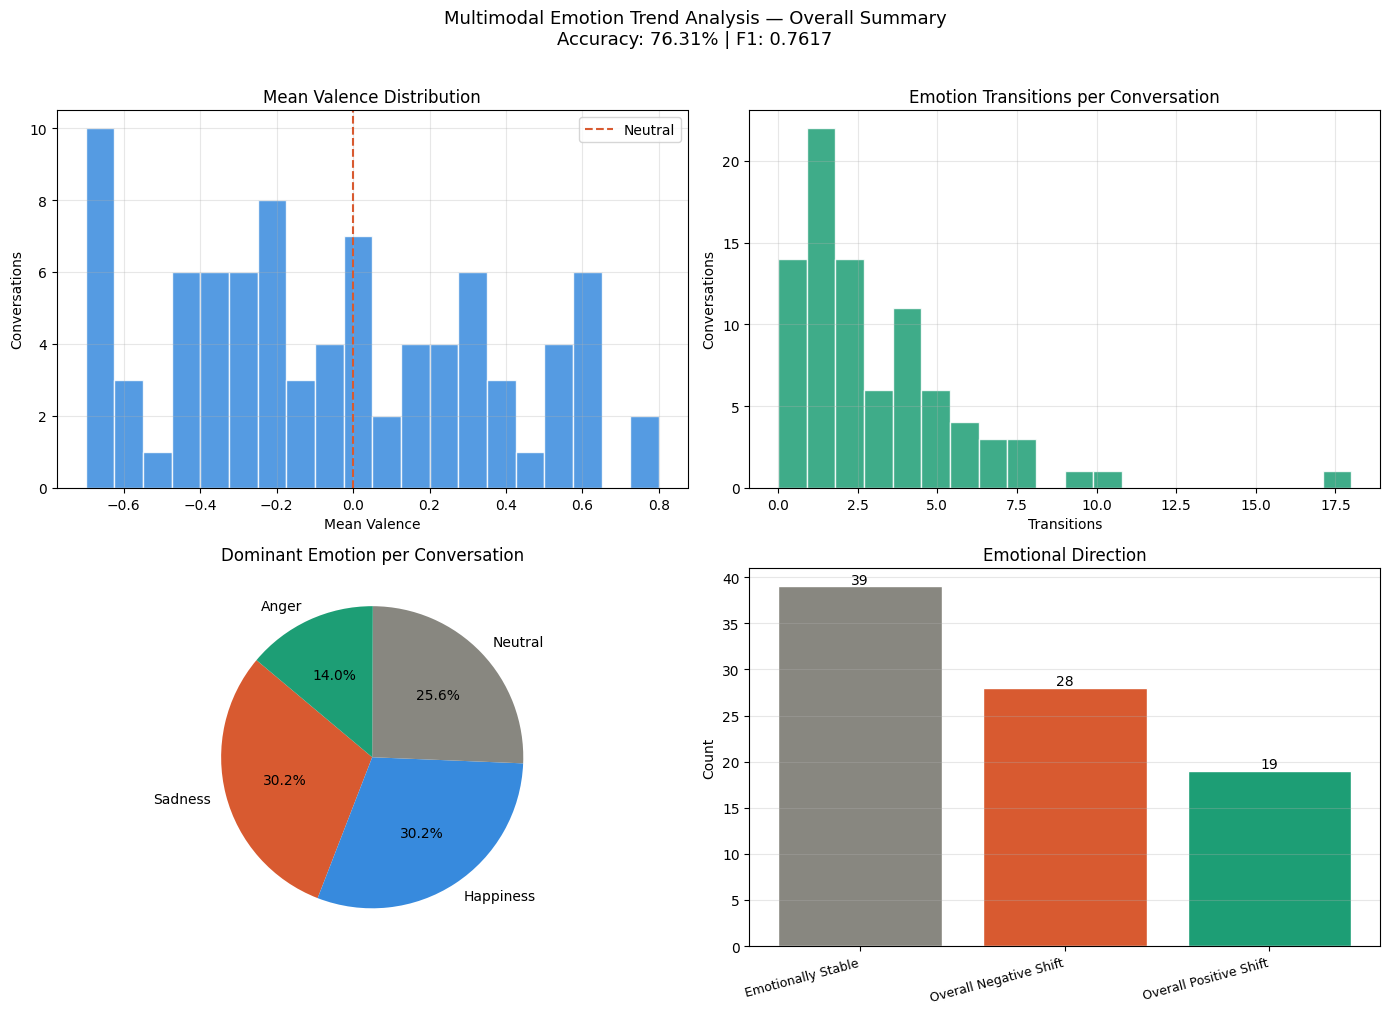

✅ Summary dashboard saved!

All outputs in: /content/drive/MyDrive/Mini Project/emotion_project/multimodal/outputs
  → multimodal_best.pt
  → metrics.json
  → confusion_matrix.png
  → roc_curve.png
  → training_curves.png
  → emotion_trend_stats.csv
  → overall_summary.png
  → conversation_plots/ (first 10)


In [ ]:
# ============================================================
# CELL 14: Save stats CSV and overall summary dashboard
# ============================================================

stats_df = pd.DataFrame(all_stats)
stats_df.to_csv(f'{OUTPUT_DIR}/emotion_trend_stats.csv',
                index=False)
print("✅ Stats saved!")

# ── Summary dashboard ──
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0,0].hist(stats_df['mean_valence'], bins=20,
               color='#378ADD', edgecolor='white', alpha=0.85)
axes[0,0].axvline(x=0, color='#D85A30',
                  linestyle='--', lw=1.5, label='Neutral')
axes[0,0].set_title('Mean Valence Distribution', fontsize=12)
axes[0,0].set_xlabel('Mean Valence', fontsize=10)
axes[0,0].set_ylabel('Conversations', fontsize=10)
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

axes[0,1].hist(stats_df['num_transitions'], bins=20,
               color='#1D9E75', edgecolor='white', alpha=0.85)
axes[0,1].set_title('Emotion Transitions per Conversation',
                    fontsize=12)
axes[0,1].set_xlabel('Transitions', fontsize=10)
axes[0,1].set_ylabel('Conversations', fontsize=10)
axes[0,1].grid(alpha=0.3)

dom_counts = stats_df['dominant_emotion'].value_counts()
pie_colors = ['#D85A30', '#378ADD', '#888780', '#1D9E75']
axes[1,0].pie(
    dom_counts.values,
    labels=dom_counts.index,
    colors=pie_colors[:len(dom_counts)],
    autopct='%1.1f%%', startangle=140,
    textprops={'fontsize': 10})
axes[1,0].set_title('Dominant Emotion per Conversation',
                    fontsize=12)

trend_counts = stats_df['trend_direction'].value_counts()
trend_colors = ['#1D9E75' if 'Positive' in t
                else '#D85A30' if 'Negative' in t
                else '#888780'
                for t in trend_counts.index]
bars = axes[1,1].bar(
    range(len(trend_counts)),
    trend_counts.values,
    color=trend_colors, edgecolor='white')
axes[1,1].set_xticks(range(len(trend_counts)))
axes[1,1].set_xticklabels(
    trend_counts.index, rotation=15,
    ha='right', fontsize=9)
axes[1,1].set_title('Emotional Direction', fontsize=12)
axes[1,1].set_ylabel('Count', fontsize=10)
axes[1,1].grid(axis='y', alpha=0.3)
for bar, v in zip(bars, trend_counts.values):
    axes[1,1].text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.3,
        str(v), ha='center', fontsize=10)

plt.suptitle(
    f'Multimodal Emotion Trend Analysis — Overall Summary\n'
    f'Accuracy: {test_acc*100:.2f}% | F1: {test_f1:.4f}',
    fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/overall_summary.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Summary dashboard saved!")
print(f"\nAll outputs in: {OUTPUT_DIR}")
print(f"  → multimodal_best.pt")
print(f"  → metrics.json")
print(f"  → confusion_matrix.png")
print(f"  → roc_curve.png")
print(f"  → training_curves.png")
print(f"  → emotion_trend_stats.csv")
print(f"  → overall_summary.png")
print(f"  → conversation_plots/ (first 10)")